In [1]:
from anomalouslib.models.model_handler import save_model, load_model, get_class_def_from_notebook
from anomalouslib.models.testing_utils import evaluate_continuous, predict_continuous
from anomalouslib.data.preprocessing import generate_classification_tensors
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.models.training_utils import train_model
from sklearn.preprocessing import LabelEncoder

from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
import pandas as pd
import torch
import dill

In [2]:
dg = DatasetGenerator(num_particules=10000)

generators = [
    ("rw", dg.generate_RandomWalk),
    ("bm", dg.generate_BrownianMotion),
    ("ctrw", dg.generate_ContinuousTimeRandomWalk),
    ("fbm", dg.generate_FractionalBrownianMotion),
    ("lw", dg.generate_LevyWalks),
    ("attm", dg.generate_AnnealedTransitTimeModel),
    ("sbm", dg.generate_ScaledBrownianMotion),
]

dataframes = []
for prefix, func in generators:
    df = func(random_params=True, num_passos=200)
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)
data

c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousApp\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


1.5


,coords,num_steps,attributes
0,"[[0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 1.0, 1.0, 1.0,...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
1,"[[0.0, -1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
2,"[[0.0, 1.0, 2.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0,...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
3,"[[0.0, 0.0, -1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
4,"[[0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 2.0,...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
...,...,...,...
69995,"[[0.6349970038793082, -0.5475305037099636, 0.7...",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69996,"[[-0.4388889377219629, -1.3447538086059247, 0....",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69997,"[[0.015129461896509497, -0.8206234833930888, -...",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69998,"[[0.8115288205254498, 1.99579815903757, 0.5552...",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."


In [3]:
def generate_classification_tensors(dataframe, parm_to_eval: str, le = LabelEncoder()):
    from sklearn.preprocessing import LabelEncoder
    import torch.nn.functional as F
    import numpy as np
    import torch
    # dataframe = dataframe.drop(columns=['num_steps', 'attributes'])
    dataframe = dataframe.sample(frac=1).reset_index(drop=True)

    # Tractem les coordenades per aconseguir X_tensor
    coords_list = [np.stack([row[0], row[1]], axis=1) for row in dataframe['coords']]
    X = np.array(coords_list)  # Forma (n_samples, seq_length, 2)
    X_tensor = torch.tensor(X, dtype=torch.float32).permute(0, 2, 1)

    # Tractem les coordenades per aconseguir y_tensor
    labels_raw = dataframe["attributes"].apply(lambda x: x[parm_to_eval])
    le.fit(labels_raw)
    labels = le.transform(labels_raw)
    labels_tensor = torch.tensor(labels, dtype=torch.long)
    y_tensor = F.one_hot(labels_tensor, num_classes=7).float()

    return X_tensor, y_tensor

In [4]:
le = LabelEncoder()
X_tensor, y_tensor = generate_classification_tensors(data, 'trajectory_type', le)

In [5]:
# Aconseguir X_train, X_val, X_test, y_train, y_val i y_test
n, train_end, val_end = len(X_tensor), int(0.7 * len(X_tensor)), int(0.85 * len(X_tensor))
X_train, X_val, X_test = X_tensor[:train_end], X_tensor[train_end:val_end], X_tensor[val_end:]
y_train, y_val, y_test = y_tensor[:train_end], y_tensor[train_end:val_end], y_tensor[val_end:]

In [6]:
# Muntem els Data_loaders
learning_batch_size = 32
try_batch_size = 1

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=learning_batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=try_batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=try_batch_size, shuffle=True)

In [7]:
class TrajectoryTypeClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super().__init__()
        # Bloque 1: 32 canales
        self.bn1_1 = nn.BatchNorm1d(32)
        self.bn1_2 = nn.BatchNorm1d(32)
        self.bn1_3 = nn.BatchNorm1d(32)
        # Bloque 2: 64 canales
        self.bn2_1 = nn.BatchNorm1d(64)
        self.bn2_2 = nn.BatchNorm1d(64)
        self.bn2_3 = nn.BatchNorm1d(64)
        # Bloque 3: 128 canales
        self.bn3_1 = nn.BatchNorm1d(128)
        self.bn3_2 = nn.BatchNorm1d(128)
        self.bn3_3 = nn.BatchNorm1d(128)

        # Primer bloc convolucional
        self.first_conv = nn.Conv1d(input_channels, 32, kernel_size=3, padding=1, dilation=1) # padding = dilation*(kernel_size-1)/2 = 4
        self.conv1_32 = nn.Conv1d(32, 32, kernel_size=3, padding=2, dilation=2)
        self.conv2_32 = nn.Conv1d(32, 32, kernel_size=5, padding=4, dilation=2)

        # Segundo bloque convolucional
        self.conv_32_64 = nn.Conv1d(32, 64, kernel_size=3, padding=2, dilation=2)
        self.conv1_64 = nn.Conv1d(64, 64, kernel_size=3, padding=4, dilation=4)
        self.conv2_64 = nn.Conv1d(64, 64, kernel_size=5, padding=8, dilation=4)

        # Tercer bloque convolucional
        self.conv_64_128 = nn.Conv1d(64, 128, kernel_size=3, padding=4, dilation=4)
        self.conv1_128 = nn.Conv1d(128, 128, kernel_size=3, padding=8, dilation=8)
        self.conv2_128 = nn.Conv1d(128, 128, kernel_size=5, padding=16, dilation=8)

        # Capas de pooling y fully connected
        self.max_pool = nn.MaxPool1d(2)
        self.avg_pool = nn.AdaptiveAvgPool1d(4)
        self.fc1 = nn.Linear(128 * 4, 512)
        self.dropout1 = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(512, 256)
        self.dropout2 = nn.Dropout(p=0.5)
        self.fc3 = nn.Linear(256, num_classes)

    def forward(self, data):
        # Bloque a
        a_resnet = F.relu(self.bn1_1(self.first_conv(data)))
        a = F.relu(self.bn1_2(self.conv1_32(a_resnet)))
        a = F.relu(self.bn1_3(self.conv2_32(a)))
        a = self.max_pool(F.relu(a + a_resnet))

        # Bloque b
        b_resnet = F.relu(self.bn2_1(self.conv_32_64(a)))
        b = F.relu(self.bn2_2(self.conv1_64(b_resnet)))
        b = F.relu(self.bn2_3(self.conv2_64(b)))
        b = self.max_pool(F.relu(b + b_resnet))

        # Bloque c
        c_resnet = F.relu(self.bn3_1(self.conv_64_128(b)))
        c = F.relu(self.bn3_2(self.conv1_128(c_resnet)))
        c = F.relu(self.bn3_3(self.conv2_128(c)))
        c = self.avg_pool(F.relu(c + c_resnet))

        # Aplanar la salida
        c = c.view(c.size(0), -1)

        # Capas fully connected
        c = F.relu(self.fc1(c))
        c = self.dropout1(c)
        c = F.relu(self.fc2(c))
        c = self.dropout2(c)
        c = self.fc3(c)
        return c


In [8]:
import json

with open("TrajectoryTypeClassifier.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)
model_source = nb["cells"][5]["source"]
if isinstance(model_source, list):
    model_source = "".join(model_source)

print(model_source)

# Muntem els Data_loaders
learning_batch_size = 32
try_batch_size = 1

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=learning_batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=try_batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=try_batch_size, shuffle=True)


In [9]:
input_channels = 2

# Inicialitzem el model d'aquesta manera per poder després guardar facilment els paràmetres
model_params = {
    "input_channels": input_channels,
    "num_classes": len(le.classes_)
}

model = TrajectoryTypeClassifier(**model_params)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 9. Entrenar el modelo
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        # print(outputs, labels)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/5], Loss: 0.2627
Epoch [2/5], Loss: 0.2271
Epoch [3/5], Loss: 0.2318
Epoch [4/5], Loss: 0.2506
Epoch [5/5], Loss: 0.2161


In [16]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_test, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.8336


S'ha d'actualitzar save_model
```python
def save_model(model_instance, model_type,  model_source, params, input_channels, model_name=None, path=None, le=None):
    if model_name is None:
        model_name = model_instance.__class__.__name__
    filename = f"{model_name}.pth"
    if path is not None:
        os.makedirs(path, exist_ok=True)
        save_path = os.path.join(path, filename)
    else:
        save_path = filename
    torch.save({
        "model_name": model_name,
        "model_type": model_type,
        "model_source": model_source,
        "state_dict": model_instance.state_dict(),
        "params": params,
        "input_channels": input_channels
        , **({"le": le} if le is not None else {})
    }, save_path, pickle_module=dill)
```

In [14]:
save_model(model_instance=model,
           model_type="classifier",
           model_source=model_source,
           params=model_params,
           input_channels=input_channels,
           le=le
           )

In [17]:
def load_model(model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(model_path, map_location=device, pickle_module=dill)
    
    # Ejecutar el código fuente para recrear la clase
    exec(checkpoint["model_source"], globals())  # La clase se define en el scope global
    
    # Instanciar el modelo con sus argumentos originales
    model_class = globals()[checkpoint["model_source"].split("class ")[1].split("(")[0].strip()]
    model = model_class(**checkpoint["params"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()
    if checkpoint["le"] is not None:
        return model, checkpoint["le"]
    return model

loaded_model, le=load_model(
    "TrajectoryTypeClassifier.pth"
)

In [18]:
loaded_model.eval()
with torch.no_grad():
    test_outputs = loaded_model(X_test)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_test, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.8428


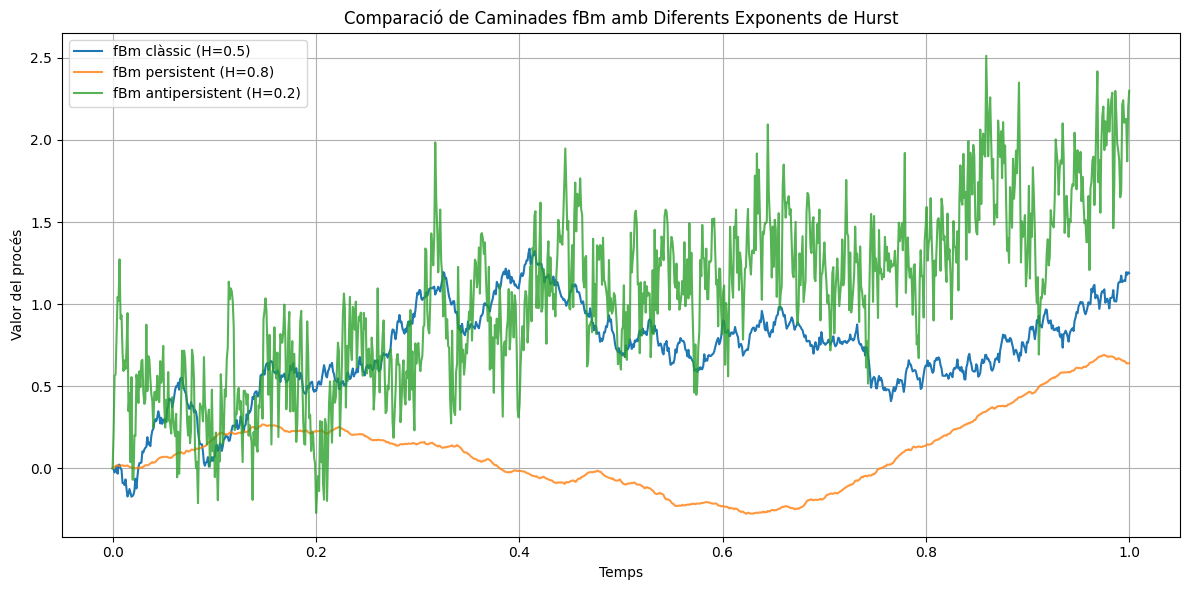

In [ ]:
from fbm import FBM
import matplotlib.pyplot as plt

n = 1024
length = 1.0
times = np.linspace(0, length, n + 1)

fbm_05 = FBM(n=n, hurst=0.5, length=length, method='cholesky')
path_h_05 = fbm_05.fbm()

fbm_08 = FBM(n=n, hurst=0.8, length=length, method='cholesky')
path_h_08 = fbm_08.fbm()

fbm_02 = FBM(n=n, hurst=0.2, length=length, method='cholesky')
path_h_02 = fbm_02.fbm()

plt.figure(figsize=(12, 6))
plt.plot(times, path_h_05, label='fBm clàssic (H=0.5)')
plt.plot(times, path_h_08, label='fBm persistent (H=0.8)', alpha=0.8)
plt.plot(times, path_h_02, label='fBm antipersistent (H=0.2)', alpha=0.8)
plt.title('Comparació de Caminades fBm amb Diferents Exponents de Hurst')
plt.xlabel('Temps')
plt.ylabel('Valor del procés')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
